In [ ]:
from google.colab import files
uploaded = files.upload()


Saving UP_Heatwave_RAW_data_clean (5).csv to UP_Heatwave_RAW_data_clean (5).csv


In [ ]:
import pandas as pd
import numpy as np
filename = next(iter(uploaded))

In [ ]:
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nStatistical summary:")
print(df.describe())

Dataset loaded successfully!

First 5 rows:
         date  T2M_MAX  T2M_MIN      T2M     RH2M    QV2M   TSOIL1  \
0  1984-01-01  21.0984   7.3688  14.1904  51.0924  5.3304  13.8684   
1  1984-01-02  16.3244   9.3172  12.5356  78.1076  7.4600  13.7500   
2  1984-01-03  21.2220   9.3640  14.1240  75.3128  7.7220  14.4436   
3  1984-01-04  23.0212   8.1280  15.1280  60.8104  6.5568  14.3704   
4  1984-01-05  19.7172   9.1048  14.5516  75.8072  8.1020  14.2064   

   ALLSKY_SFC_SW_DWN  CLRSKY_SFC_SW_DWN  CLOUD_AMT  ...  GWETROOT   WS10M  \
0           2.110604           4.484732     79.820  ...    0.4780  2.3824   
1           1.192184           4.717732     99.900  ...    0.4780  2.3024   
2           2.139228           4.643500     64.564  ...    0.4880  2.2360   
3           3.977552           4.366952     25.184  ...    0.4944  1.7380   
4           4.024808           4.510568     50.788  ...    0.4944  2.0968   

     WD10M       PS  PRECTOTCORR       TS  EVLAND    city   lat   lon  


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


Activity 1:

In [ ]:
columns = ['T2M', 'T2M_MAX', 'T2M_MIN', 'RH2M']

data = df[columns].replace([np.inf, -np.inf], np.nan).dropna()

data = data.sample(n=min(10000, len(data)), random_state=42)
data = data.reset_index(drop=True)

print("Dataset prepared successfully!")
print("Number of observations:", len(data))
print("\nSelected variables:")
print(columns)

Dataset prepared successfully!
Number of observations: 10000

Selected variables:
['T2M', 'T2M_MAX', 'T2M_MIN', 'RH2M']


In [ ]:
np.random.seed(42)

all_indices = np.random.permutation(len(data))
test_size = int(0.20 * len(data))

test_indices = all_indices[:test_size]
train_indices = all_indices[test_size:]

train_data = data.iloc[train_indices]
test_data = data.iloc[test_indices]

print("\nTraining observations:", len(train_data))
print("Simulated missing values:", len(test_data))


Training observations: 8000
Simulated missing values: 2000


In [ ]:
def evaluate_model(actual, predicted):
    errors = actual - predicted

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    ss_total = np.sum((actual - np.mean(actual)) ** 2)
    ss_residual = np.sum(errors ** 2)

    r2 = 1 - ss_residual / ss_total if ss_total != 0 else np.nan

    return mae, rmse, r2

In [ ]:
x_train = train_data['T2M_MAX'].to_numpy()
y_train = train_data['T2M'].to_numpy()

x_test = test_data['T2M_MAX'].to_numpy()
y_test = test_data['T2M'].to_numpy()

# Calculate regression coefficients manually
x_mean = np.mean(x_train)
y_mean = np.mean(y_train)

numerator = np.sum((x_train - x_mean) * (y_train - y_mean))
denominator = np.sum((x_train - x_mean) ** 2)

if denominator == 0:
    raise ValueError("Predictor has no variation.")

b1 = numerator / denominator
b0 = y_mean - b1 * x_mean

In [ ]:
simple_predictions = b0 + b1 * x_test

print("Intercept (b0):", round(b0, 4))
print("Slope (b1):", round(b1, 4))
print("Regression equation:")
print(f"T2M = {b0:.4f} + ({b1:.4f} * T2M_MAX)")

mae1, rmse1, r21 = evaluate_model(y_test, simple_predictions)

print("\nSimple Regression Accuracy:")
print("MAE:", round(mae1, 4))
print("RMSE:", round(rmse1, 4))
print("R-squared:", round(r21, 4))

print("\nSample predictions:")
print(pd.DataFrame({
    'Actual T2M': y_test[:10],
    'Predicted T2M': simple_predictions[:10]
}).round(3))

Intercept (b0): -6.9172
Slope (b1): 0.9986
Regression equation:
T2M = -6.9172 + (0.9986 * T2M_MAX)

Simple Regression Accuracy:
MAE: 2.0277
RMSE: 2.3729
R-squared: 0.8889

Sample predictions:
   Actual T2M  Predicted T2M
0      26.628         21.787
1      26.888         27.979
2      31.522         30.475
3      17.632         15.963
4      14.386         15.807
5      24.438         26.527
6      30.921         32.318
7      29.129         30.073
8      23.051         21.933
9      26.888         25.929


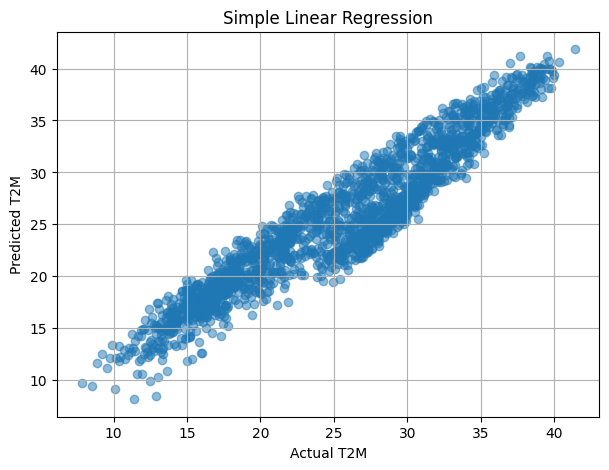

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, simple_predictions, alpha=0.5)
plt.xlabel("Actual T2M")
plt.ylabel("Predicted T2M")
plt.title("Simple Linear Regression")
plt.grid(True)
plt.show()


Activity 2 :

In [ ]:
predictors = ['T2M_MAX', 'T2M_MIN', 'RH2M']

X_train = train_data[predictors].to_numpy()
X_test = test_data[predictors].to_numpy()

Y_train = train_data['T2M'].to_numpy()
Y_test = test_data['T2M'].to_numpy()

# Add a column of ones for the intercept
X_train_matrix = np.column_stack([
    np.ones(len(X_train)), X_train
])

X_test_matrix = np.column_stack([
    np.ones(len(X_test)), X_test
])


In [ ]:
coefficients = np.linalg.pinv(X_train_matrix) @ Y_train

In [ ]:
multiple_predictions = X_test_matrix @ coefficients

print("Regression coefficients:")
print("Intercept:", round(coefficients[0], 4))

for i, name in enumerate(predictors):
    print(f"Coefficient of {name}: {coefficients[i + 1]:.4f}")

print("\nMultiple regression equation:")
print(
    f"T2M = {coefficients[0]:.4f}"
    + ''.join(
        f" + ({coefficients[i + 1]:.4f} * {name})"
        for i, name in enumerate(predictors)
    )
)

mae2, rmse2, r22 = evaluate_model(Y_test, multiple_predictions)

print("\nMultiple Regression Accuracy:")
print("MAE:", round(mae2, 4))
print("RMSE:", round(rmse2, 4))
print("R-squared:", round(r22, 4))

print("\nSample predictions:")
print(pd.DataFrame({
    'Actual T2M': Y_test[:10],
    'Predicted T2M': multiple_predictions[:10]
}).round(3))

Regression coefficients:
Intercept: -2.3357
Coefficient of T2M_MAX: 0.5417
Coefficient of T2M_MIN: 0.5149
Coefficient of RH2M: 0.0047

Multiple regression equation:
T2M = -2.3357 + (0.5417 * T2M_MAX) + (0.5149 * T2M_MIN) + (0.0047 * RH2M)

Multiple Regression Accuracy:
MAE: 0.3072
RMSE: 0.4015
R-squared: 0.9968

Sample predictions:
   Actual T2M  Predicted T2M
0      26.628         26.450
1      26.888         27.195
2      31.522         32.017
3      17.632         17.401
4      14.386         14.138
5      24.438         24.792
6      30.921         31.250
7      29.129         29.312
8      23.051         23.039
9      26.888         26.889


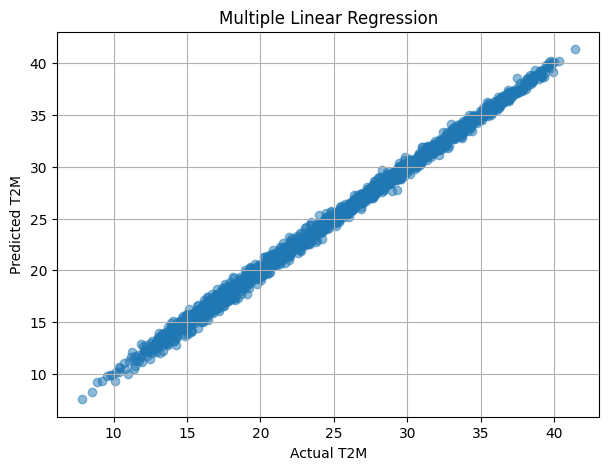

In [ ]:
plt.figure(figsize=(7, 5))
plt.scatter(Y_test, multiple_predictions, alpha=0.5)
plt.xlabel("Actual T2M")
plt.ylabel("Predicted T2M")
plt.title("Multiple Linear Regression")
plt.grid(True)
plt.show()

Activity 3:

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Simple Linear Regression',
              'Multiple Linear Regression'],
    'MAE': [mae1, mae2],
    'RMSE': [rmse1, rmse2],
    'R-squared': [r21, r22]
})

print(comparison.round(4).to_string(index=False))

print("\nInterpretation:")
if mae2 < mae1:
    print("Multiple regression has lower MAE on this test sample.")
elif mae1 < mae2:
    print("Simple regression has lower MAE on this test sample.")
else:
    print("Both models have equal MAE on this test sample.")

print("Lower MAE and RMSE indicate smaller prediction errors.")
print("Higher R-squared generally indicates a better fit.")


                     Model    MAE   RMSE  R-squared
  Simple Linear Regression 2.0277 2.3729     0.8889
Multiple Linear Regression 0.3072 0.4015     0.9968

Interpretation:
Multiple regression has lower MAE on this test sample.
Lower MAE and RMSE indicate smaller prediction errors.
Higher R-squared generally indicates a better fit.
